# 3 · A residual upscaler

Notebook 2's plain CNN makes the whole picture itself. This one is **residual**: bicubic makes the picture, and the
network only learns a correction that is added to it. Its last layer starts at zero, so the untrained model *is*
bicubic and training starts from there. `models.PlainUpscaler` 32-16, the shape the client ships.

Trained with the shared recipe (`training.fit`) at three seeds, and the run that does best on the select split is
kept: one seed can stall at bicubic (section 2). All three are scored on notebook 0's validation split like every
notebook, so they sit in one table with notebook 2's plain CNNs. Then the kept model's float16 graph, the one a browser
GPU runs, is scored the same way.

Needs: `00_data_preprocess.ipynb`, `01_upscale_dummy.ipynb` (bicubic's scores) and `02_upscale_nn.ipynb` (the plain
CNNs' scores). Writes `checkpoints/web_runs/`, which `04_upscale_strategies.ipynb` (the control) and
`05_upscale_geometry.ipynb` (the kept run) use.

In [1]:
"""Settings."""

import os

import numpy as np
import torch

os.environ["DATASETS_DIR"] = "/mnt/d/datasets"   # where the datasets are: set before helpers is imported

from helpers import models, speed, training, webexport
from helpers.training import DEVICE

NOTEBOOK = 3
NAME = "residual 32-16"
WIDTHS = (32, 16)   # channels of the body's convolutions
STEM = 5            # kernel size of the first convolution; the ones after it are 3x3
SKIP = 5            # kernel size of the bicubic skip (bicubic x2 needs 4 taps; 5 is the smallest odd size)
SEEDS = (0, 1, 2)
RUN_DIR = training.CHECKPOINT_DIR / "web_runs"   # one training a seed, saved every epoch

manifest = training.load_manifest()
SCALE = manifest["scale"]
bicubic = training.recorded()[1, "bicubic"]   # notebook 1's scores of the bar

## 1. The model

    LR --> bicubic skip (fixed 5x5 conv) ---------------------------+
    LR --> conv 5x5 -> ReLU -> conv 3x3 -> ReLU -> output conv 3x3 --+--> add --> PixelShuffle --> HR

- **Bicubic as a convolution.** Bicubic ×2 is linear and the same everywhere, which is what a convolution is: each of
  the 4 output sub-pixels is a fixed filter of the input (`models.BicubicSkip`, frozen). The browser runs `Conv` fast
  and `Resize` slowly (notebook 1's export).
- **Added at low resolution.** Both branches are added *before* the `PixelShuffle`: one shuffle, and a quarter of the
  pixels to add.
- **Starts as bicubic.** The output convolution starts at zero, so the network only has to learn the correction.

**Halo.** The 5×5 reaches 2 pixels, each 3×3 after it 1: 4 in all, the halo of the patches and of the client's tiles.

In [2]:
print(f"conv skip vs F.interpolate: {models.check_skip_is_bicubic(SCALE, SKIP):.1e} apart (float32 rounding)")

def build(seed):
    torch.manual_seed(seed)
    return models.PlainUpscaler(WIDTHS, STEM, SKIP, SCALE).to(DEVICE)


def run_name(seed):
    return f"{NAME}, seed {seed}"


def run_file(seed):
    return RUN_DIR / f"residual_32-16_seed{seed}.pt"


model = build(0)
assert model.halo <= manifest["halo"], "the model reaches further than the patches' halo"
trim = training.trimmer(manifest)   # cuts the halo off an output: the border is padding, not picture
x = torch.rand(8, 3, manifest["input_lr"], manifest["input_lr"], device=DEVICE)
with torch.no_grad(), training.full_precision():
    start = (trim(model(x)) - trim(models.bicubic(x, SCALE))).abs().max().item()
assert start < 1e-5, f"the untrained model is not bicubic ({start:.1e})"
print(f"{models.count_parameters(model):,} parameters ({models.count_parameters(model, learned_only=True):,} "
      f"learned), halo {model.halo}, {speed.macs_per_lr_pixel(model):,.0f} multiply-adds per LR pixel")

conv skip vs F.interpolate: 2.4e-07 apart (float32 rounding)
9,696 parameters (8,796 learned), halo 4, 9,636 multiply-adds per LR pixel


## 2. Train

The same `training.fit` as notebook 2: Adam at 1e-3, batches of 32, `metrics.ssim_l1_loss`, epochs of 34,368 patches,
the best epoch by SSIM-Y on the select split, halving at plateaus until it converges. The model starts at bicubic, so
its curve starts on the bicubic line, not far below it.

**Three seeds** (other starting weights, other batches), each saved to `checkpoints/web_runs/`. A run can stall at
bicubic: if the first epochs push the narrow layer's units below zero for every input, their ReLUs pass nothing and no
gradient reaches them again. The run with the best select SSIM-Y is kept (`training.best_run`), chosen without the
validation split; notebook 4 uses all three as its control.

train  140795 patches
select   6982 patches, to choose the best epoch
residual 32-16, seed 0   best epoch  44 of  62, select SSIM-Y 0.8573
train  140795 patches
select   6982 patches, to choose the best epoch
residual 32-16, seed 1   best epoch 103 of 121, select SSIM-Y 0.8817
train  140795 patches
select   6982 patches, to choose the best epoch
residual 32-16, seed 2   best epoch 104 of 116, select SSIM-Y 0.8837
kept: seed 2


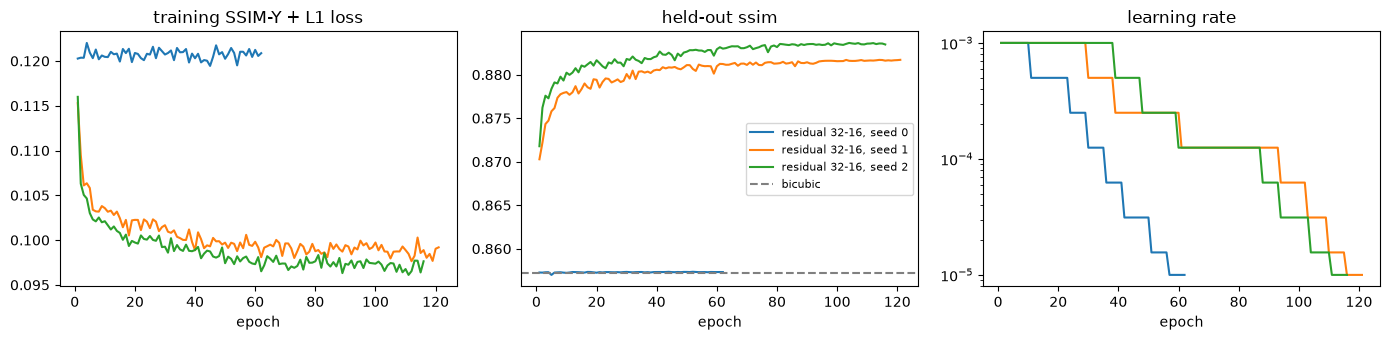

In [3]:
runs, histories = {}, {}
for seed in SEEDS:
    runs[seed] = build(seed)
    histories[run_name(seed)], best = training.fit(runs[seed], run_file(seed), manifest, seed=seed, verbose=0)
    print(f"{run_name(seed):<24} best epoch {best['epoch']:3} of {len(histories[run_name(seed)]):3}, "
          f"select SSIM-Y {best['score']:.4f}")
kept_file = training.best_run([run_file(seed) for seed in SEEDS])
KEPT = next(seed for seed in SEEDS if run_file(seed) == kept_file)
model = runs[KEPT].eval()
print(f"kept: seed {KEPT}")
training.plot_history(histories, training.select_bicubic(manifest), key="ssim", loss_name="SSIM-Y + L1 loss")

## 3. Scores

Every seed on the validation split, beside notebook 2's plain CNNs from their recorded scores.

In [4]:
results = {"bicubic": bicubic, **{name: scores for (notebook, name), scores in training.recorded().items()
                                  if notebook == 2}}
for seed, run in runs.items():
    run.eval()
    results[run_name(seed)] = training.val_scores(lambda lr, condition: run(lr), manifest)
    training.record(NOTEBOOK, run_name(seed), results[run_name(seed)])

training.show(training.compare(results, manifest, base=bicubic))
print()
training.show(training.gain_by_qp(results, manifest, base=bicubic))

                 model SSIM-Y over bicubic          95% range luma dB dB over chroma dB over   video  screen   photo    x264   nvenc
       plain CNN 64-32 0.8872      +0.0351 +0.0328 to +0.0375   29.81   +1.23          -3.05 +0.0191 +0.0540 +0.0185 +0.0366 +0.0336
 plain CNN 16-24-24-32 0.8867      +0.0346 +0.0323 to +0.0369   29.72   +1.14          -3.66 +0.0186 +0.0535 +0.0176 +0.0360 +0.0331
residual 32-16, seed 2 0.8826      +0.0306 +0.0284 to +0.0328   29.54   +0.96          -2.70 +0.0155 +0.0484 +0.0146 +0.0315 +0.0296
residual 32-16, seed 1 0.8804      +0.0283 +0.0262 to +0.0303   29.57   +0.99          -2.55 +0.0141 +0.0454 +0.0125 +0.0289 +0.0276
residual 32-16, seed 0 0.8523      +0.0002 +0.0001 to +0.0003   28.58   -0.01          -0.05 +0.0003 +0.0001 +0.0001 +0.0002 +0.0001
               bicubic 0.8521      +0.0000 +0.0000 to +0.0000   28.58   +0.00          +0.00 +0.0000 +0.0000 +0.0000 +0.0000 +0.0000

                 model    0-18   18-26   26-30   30-34   34-38   38-

### What it looks like

The kept run on four validation screens at a slice QP under 26.

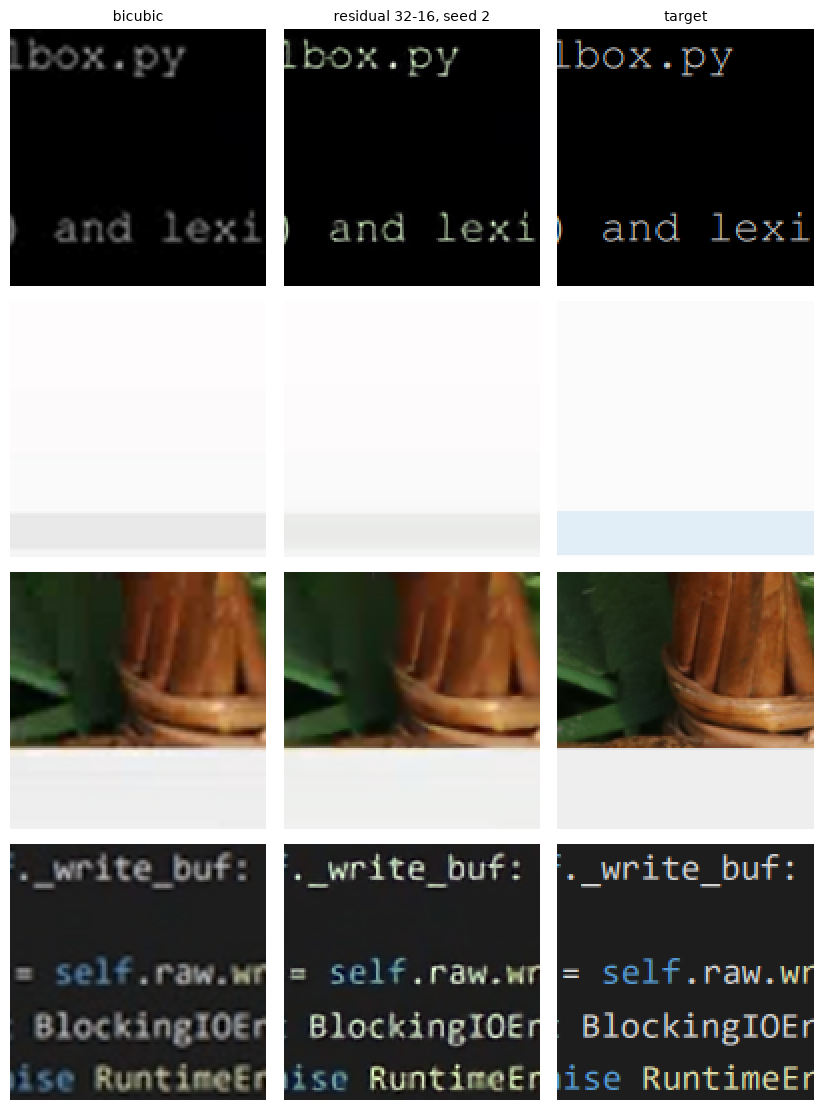

In [5]:
lr, hr = training.val_screens(manifest)
with torch.no_grad():
    training.show_patches({"bicubic": trim(models.bicubic(lr, SCALE)), run_name(KEPT): trim(model(lr)), "target": hr})

## 4. Export for the browser

The kept run, at the client's tile (320×180 LR pixels a step plus the halo of 4) and as a whole 1080p frame, in float32 and float16
(half the size; the desktop CPU has no float16 kernels, so it is only faster on a GPU). Each is checked against torch
and timed on this CPU.

In [6]:
webexport.publish(model, "upscale_web", model.halo, label=f"web {'-'.join(map(str, WIDTHS))}", scale=SCALE,
                  float16=True)
print("compare in a browser: uv run src/upscale/benchmark/main.py")

upscale_web_tile320x180.onnx                           39.3 KB    6.01 ms   Addx1, Convx4, DepthToSpacex1, Relux2
upscale_web_tile320x180_frame.onnx                     39.7 KB   56.88 ms   Addx1, Convx4, DepthToSpacex1, Relux2
upscale_web_fp16_tile320x180.onnx                      20.7 KB    7.62 ms   Addx1, Convx4, DepthToSpacex1, Relux2
upscale_web_fp16_tile320x180_frame.onnx                20.8 KB   50.00 ms   Addx1, Convx4, DepthToSpacex1, Relux2
compare in a browser: uv run src/upscale/benchmark/main.py


### What float16 costs

The float16 graph, run by onnxruntime on every validation patch and scored like the model.

In [7]:
evaluation = training.CHECKPOINT_DIR / "evaluation"
any_size = webexport.export(model, "web_dynamic.onnx", manifest["input_lr"], halo=model.halo, dynamic=True,
                            models_dir=evaluation)
half = webexport.OnnxModel(webexport.to_float16(any_size, "web_dynamic_fp16.onnx", models_dir=evaluation)["path"],
                           np.float16)
graph = {f"{run_name(KEPT)}, float16 graph": training.val_scores(lambda lr, condition: half(lr), manifest)}
training.show(training.compare({run_name(KEPT): results[run_name(KEPT)], **graph}, manifest, base=bicubic))

                                model SSIM-Y over bicubic          95% range luma dB dB over chroma dB over   video  screen   photo    x264   nvenc
               residual 32-16, seed 2 0.8826      +0.0306 +0.0284 to +0.0328   29.54   +0.96          -2.70 +0.0155 +0.0484 +0.0146 +0.0315 +0.0296
residual 32-16, seed 2, float16 graph 0.8826      +0.0305 +0.0284 to +0.0328   29.54   +0.96          -2.71 +0.0155 +0.0484 +0.0146 +0.0315 +0.0296


## 5. What it says

- **One seed in three stalled at bicubic.** Seed 0 ended at 0.8573 on the select split, bicubic's own score, and
  scores +0.0002 on the validation split: 11 of the narrow layer's 16 ReLUs never fire, and the correction stays
  near zero. Seeds 1 and 2
  learned (0.8817 and 0.8837 on the select split). Retraining this model means training more than one seed.
- **The kept run (seed 2)** scores 0.8826 SSIM-Y, +0.0306 over bicubic (95% range +0.0284 to +0.0328), and +0.96 dB
  of luma. Seed 1 lands 0.0023 lower: that much is luck.
- **Below notebook 2's plain CNNs** by 0.004 to 0.005, with fewer learned weights (8,796 against 13,404 for the
  16-24-24-32) and 9,636 multiply-adds per LR pixel against 13,296.
- **It costs colour too**: 2.7 dB of chroma PSNR under bicubic, half of it on gray screens, 0.3 dB pooled over the
  split.
- **Float16 is free.** The float16 graph scores what the model does (0.8826, 0.0001 of gain lost), at half the file.